# Ion inertial length in Jupiter's magnetosphere

In [1]:
import numpy as np
import glob as glob
import datetime as dt
import matplotlib.pyplot as plt
import re

from matplotlib.ticker import AutoMinorLocator, LogLocator, LinearLocator

from JunoPy.spice import InitSpiceKernels, get_juno_position
from JunoPy.mag import MagData

## 1. Calculate the variation of density with radial distance. 

In [2]:
r = np.linspace(6, 130, 100)

# Bagenal and Delamere (2011) model
a1 = 1987
a2 = 14
a3 = 0.05
b1 = -8.2
b2 = -3.2
b3 = -0.65

n = a1 * (r / 6)**(b1) + a2 * (r / 6)**(b2) + a3 * (r / 6)**(b3) 


mi = 16.6 * 1.67e-27
qi = 1.6e-19
rhoi = mi * n * 1e6
mu0 = 1.25e-6
e = 1.6e-19
di = 3e8 / np.sqrt(e**2 * n * 1e6 / mi / 8.84e-12) / 1e3 # / 71492e3
# di = mi / qi * np.sqrt(1 / rhoi / mu0) / 71492e3

## 2. Read the csv file and estimate spacecraft velocity

In [3]:
def read_csv_file():
    start_times = []
    end_times = []
    durations = []
    with open('auto_plasmoid_list_20210525_window10.csv', 'r') as f:
        f.readline()
        for line in f:
            start_times.append(dt.datetime.strptime(line.split(',')[0].strip(), '%Y-%jT%H:%M:%S'))
            end_times.append(dt.datetime.strptime(line.split(',')[1].strip(), '%Y-%jT%H:%M:%S'))
            durations.append((end_times[-1] - start_times[-1]).total_seconds())
    return start_times, end_times, durations
            
start_times, end_times, durations = read_csv_file()
start_positions, _ = get_juno_position(start_times)
end_positions, _ = get_juno_position(end_times)

In [4]:
N = len(start_times)

deltat = [(end_times[i] - start_times[i]).seconds for i in range(N)]
# dx = np.sqrt(np.sum(start_positions**2, axis=1) - np.sum(end_positions**2, axis=1))
dx = np.sqrt(np.sum((start_positions - end_positions)**2 , axis=1)) * 71492
v = dx / deltat * 1e3 # 71492e3
r_sc = np.sqrt(np.sum(start_positions**2, axis=1))
print(deltat)

[65, 62, 45, 75, 25, 111, 159, 22, 33, 85, 24, 104, 90, 267, 16, 142, 15, 45, 61, 137, 35, 20, 27, 29, 29, 38, 25, 13, 152, 91, 94, 63, 43, 32, 16, 104, 66, 26, 32, 147, 18, 49, 16, 13, 122, 90, 118, 249, 32, 22, 232, 221, 178, 54, 40, 93, 51, 61, 15, 28, 55, 38, 23, 29, 113, 28, 23, 24, 197, 30, 73, 31, 13, 19, 37, 137, 28, 50, 144, 128, 137, 85, 17, 52, 13, 17, 43, 50]


In [5]:
dx * 71492

array([1.53075128e+07, 1.38593698e+07, 1.00466622e+07, 1.81150155e+07,
       6.24906579e+06, 2.61618102e+07, 4.14247432e+07, 6.67627309e+06,
       1.76904249e+07, 2.11338677e+07, 5.96862464e+06, 2.70393947e+07,
       2.88764742e+07, 1.36002454e+08, 3.40074350e+06, 5.10915124e+07,
       8.80249094e+06, 1.03976454e+07, 1.45717622e+07, 3.49377186e+07,
       8.66979423e+06, 5.80989662e+06, 1.02795955e+07, 1.08278043e+07,
       1.15857402e+07, 1.41872852e+07, 1.16345534e+07, 7.33700225e+06,
       3.64196571e+07, 2.13052156e+07, 2.65561411e+07, 1.78105718e+07,
       1.52022419e+07, 1.12958000e+07, 5.73889373e+06, 3.58597451e+07,
       2.95127505e+07, 1.35912552e+07, 6.60928023e+06, 3.04588387e+07,
       3.72561439e+06, 1.01184170e+07, 3.31381215e+06, 3.11659151e+06,
       3.37027742e+07, 3.29450138e+07, 2.46155933e+07, 5.57378699e+07,
       7.19496960e+06, 4.94340087e+06, 5.61936838e+07, 5.35290235e+07,
       4.82301500e+07, 1.57624753e+07, 1.20393024e+07, 2.58971148e+07,
      

## 3. Obtain the average magnetic field during the plasmoid interval.

In [6]:
def get_average_B(start_times, end_times):
    """
    """
    B = []
    
    
    for start, end in zip(start_times, end_times):    
        magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
        magdata = MagData(filename=magfile)
        magdata.df = magdata.df.loc[start - dt.timedelta(seconds=300):
                                    end + dt.timedelta(seconds=300)]
        
        B.append(magdata.df['Bmag'].mean())
        
        
    return np.asarray(B)

B_avg = get_average_B(start_times, end_times)

In [7]:
def get_deltaB(start_times, end_times):
    """
    """
    dB = []
    
    
    for start, end in zip(start_times, end_times):    
        magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
        magdata = MagData(filename=magfile)
        magdata.df = magdata.df.loc[start:end]
        
        dB.append(magdata.df['Bmag'].max()**2 - magdata.df['Bmag'].min()**2)
        
        if magdata.df['Z'][0] < -20 * 71492:
            print(start, end)
        
    return np.asarray(dB) * 1e-18 / 2 / (4 * np.pi * 1e-7) * 1e9

deltaB = get_deltaB(start_times, end_times)

2017-04-06 03:20:06 2017-04-06 03:21:31
2017-04-06 03:16:48 2017-04-06 03:17:12
2017-05-30 18:31:35 2017-05-30 18:31:51


## Plot the data.

/home/ysar/anaconda3/envs/JunoPy-das/lib/python3.7/site-packages/ipykernel_launcher.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


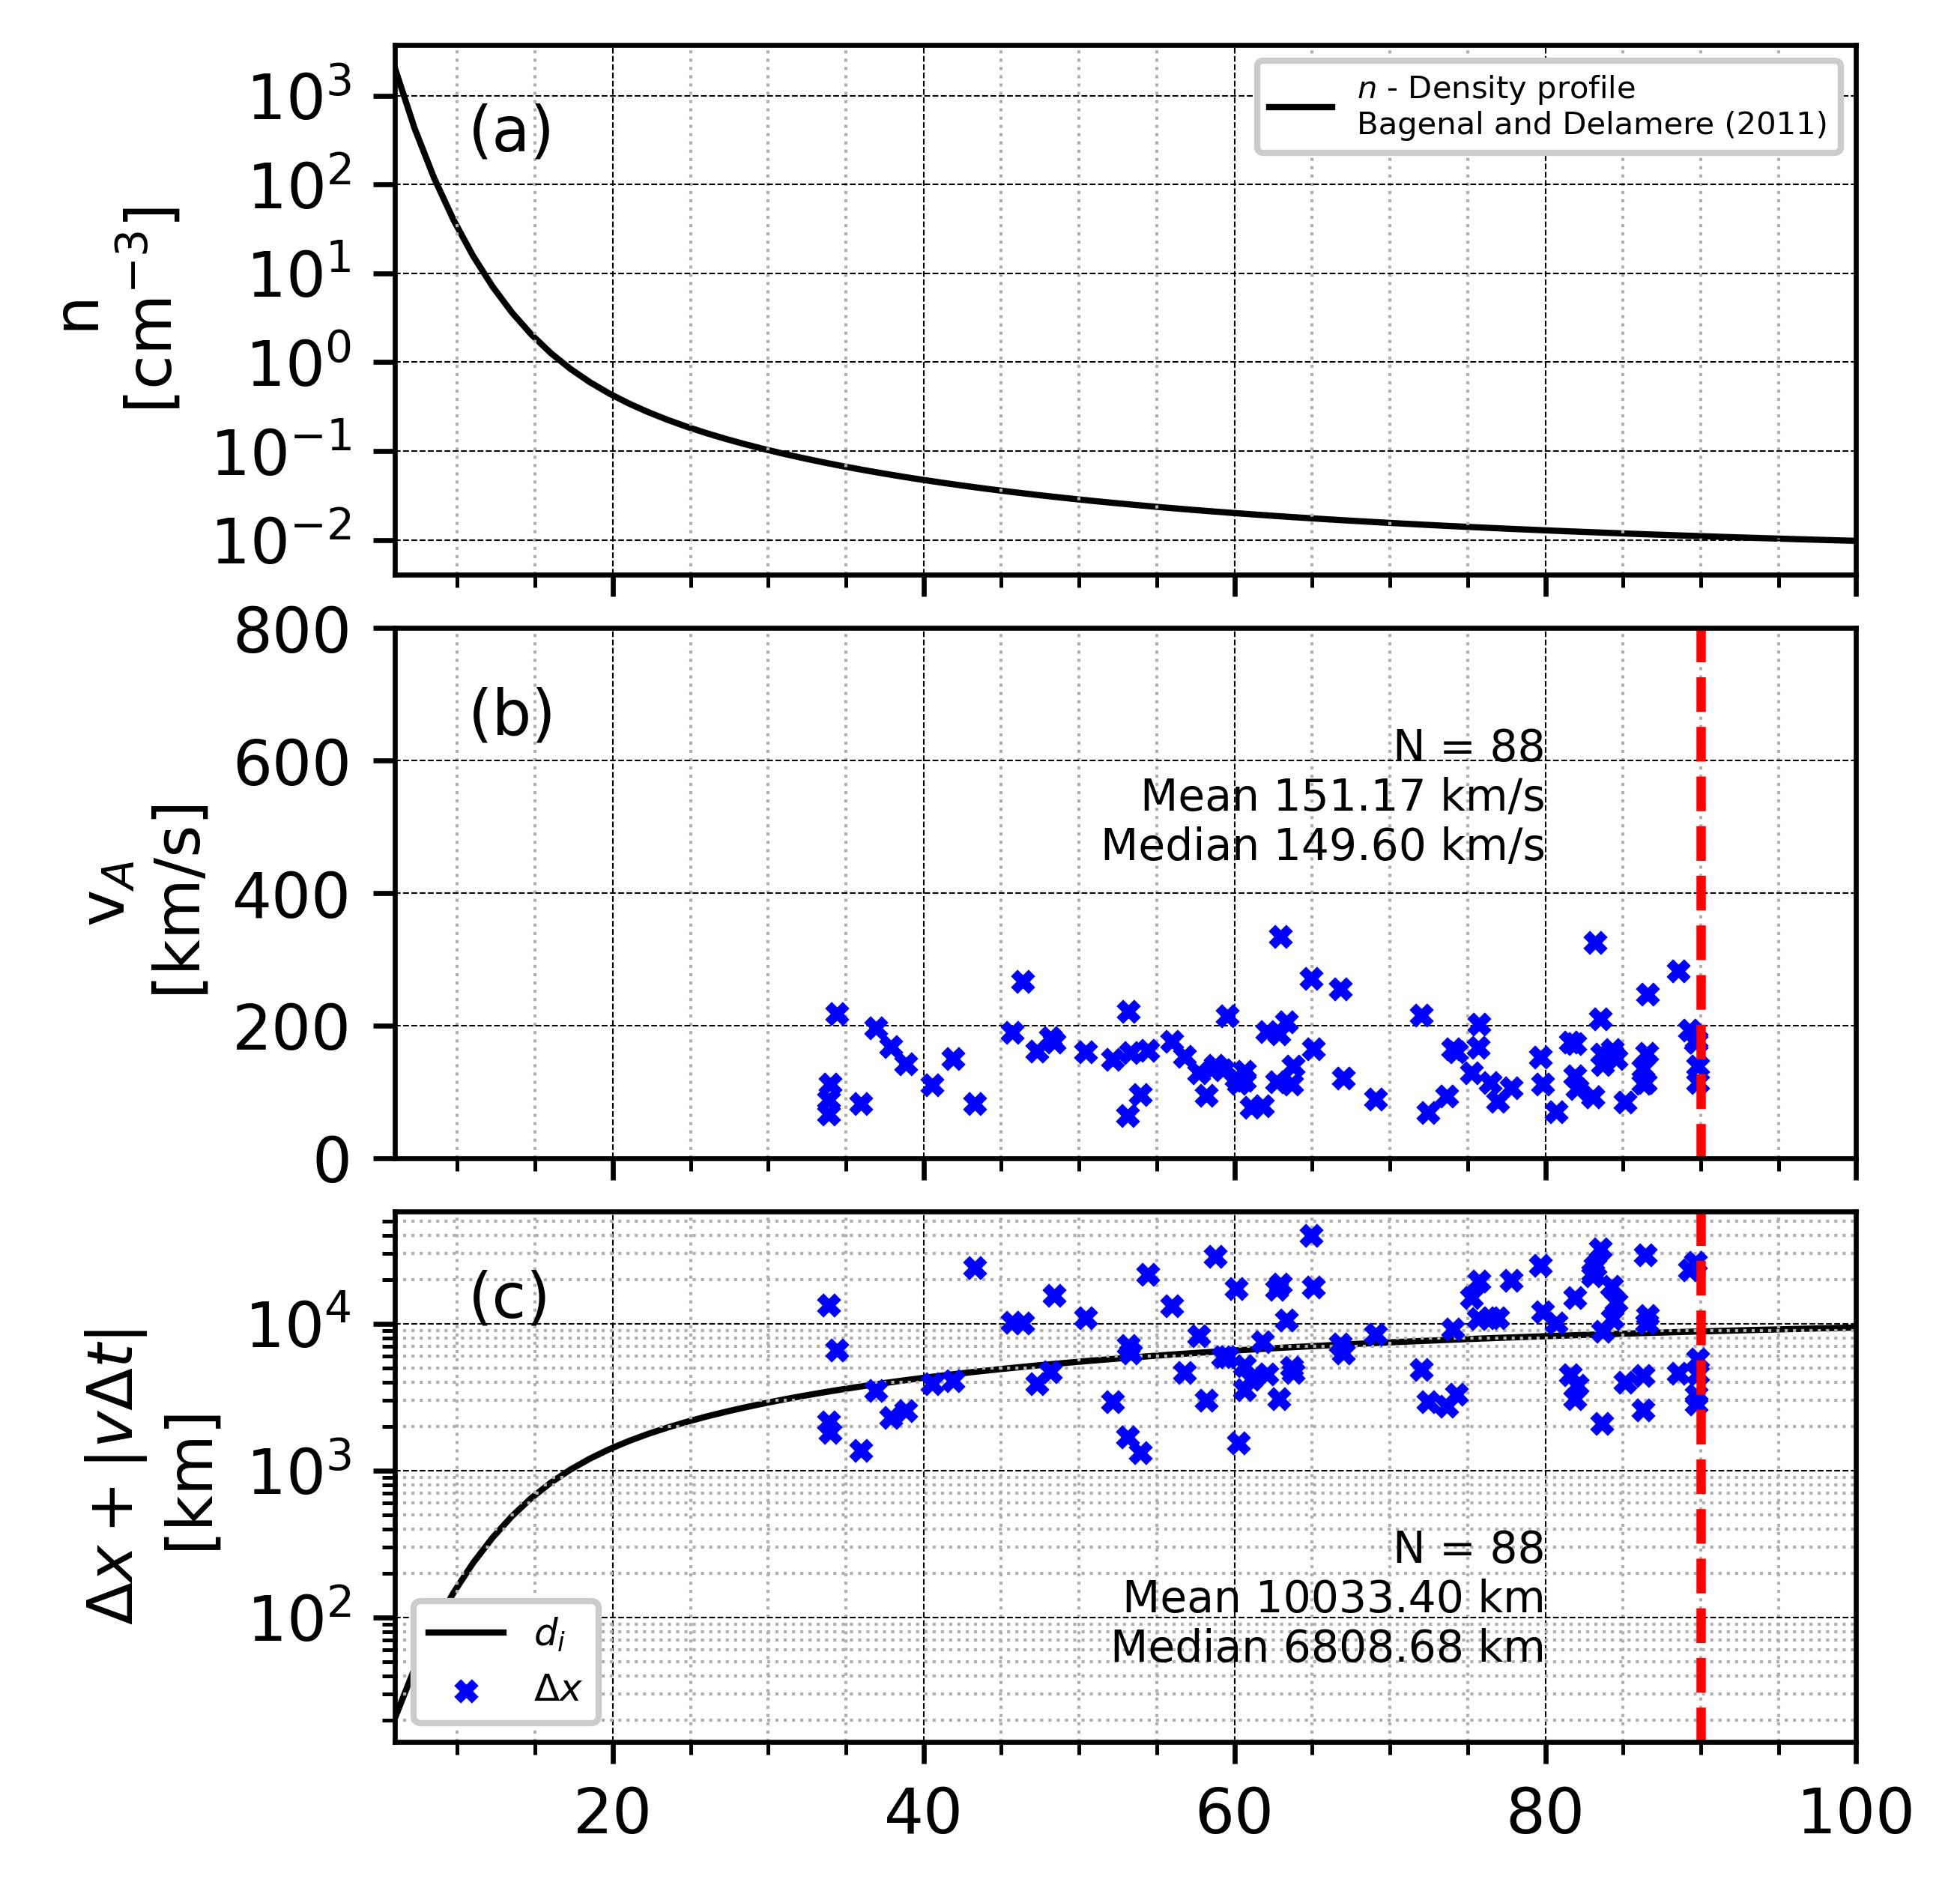

In [8]:
# fig, ax = plt.subplots(3, 1, sharex=True, dpi=600, figsize=(5,5), )

fig, ax = plt.subplots(3, 1, figsize=(5,5), dpi=600, gridspec_kw=dict(hspace=0.1, wspace=0.12, left=0.25))

# 1. Density versus Radial distance
ax[0].semilogy(r, n, color='k', zorder=1, lw=1.)
ax[0].set_ylabel('n\n[cm$^{-3}$]')
ax[0].yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax[0].legend(['$n$ - Density profile\nBagenal and Delamere (2011)',
             '$n/10$',
             '$10n$'], prop={'size': 5}, framealpha=1.0)

# 3. Alfven speed
n_sc = a1 * (r_sc / 6)**(b1) + a2 * (r_sc / 6)**(b2) + a3 * (r_sc / 6)**(b3) 
vAlfven = B_avg / np.sqrt(mu0 * mi * n_sc * 1e6) * 1e-9 / 1e3

ax[1].scatter(r_sc, vAlfven, marker='x', zorder=2, color='b', s=8.0)
ax[1].set_ylabel('v$_A$\n[km/s]')
ax[1].set_yticks([0, 200, 400, 600, 800])
ax[1].text(80, 450, 
           'N = {:d}\nMean {:.2f} km/s\nMedian {:.2f} km/s'.format(
                N, np.mean(vAlfven), np.median(vAlfven)), 
            size=7, horizontalalignment='right')


# 2. Ion inertial length
ax[2].semilogy(r, di, color='k', zorder=1, lw=1.)
ax[2].scatter(r_sc, dx + vAlfven * np.asarray(deltat), marker='x', zorder=2, color='b', s=8.0)
ax[2].set_ylabel('$\Delta x + |v\Delta t|$\n[km]')
ax[2].yaxis.set_major_locator(LogLocator(base=10, numticks=8))

ax[2].legend(['$d_i$', '$\Delta x$'], loc='lower left', prop={'size': 6}, framealpha=1.0)
ax[2].text(80, 50, 
           'N = {:d}\nMean {:.2f} km\nMedian {:.2f} km'.format(
                N, np.mean(dx + vAlfven * np.asarray(deltat)), np.median(dx + vAlfven * np.asarray(deltat))), 
           size=7, horizontalalignment='right')


# 4. Delta B 
# ax[3].scatter(r_sc, deltaB, marker='x', zorder=2, color='b', s=4.0)
# ax[3].set_ylabel('$\Delta p_B$ [nPa]')
# ax[3].set_xlabel('r [R$_J$]')
# # ax[3].set_yticks([0, 2, 4, 6])
# ax[3].text(80, 0.035, 
#            'N = {:d}\nMean {:.3f} km\nMedian {:.3f} km'.format(
#                 N, np.mean(deltaB), np.median(deltaB)), 
#            size=7, horizontalalignment='right')
# ax[3].set_xlabel('r [R$_J$]')

# Cleanup
for a in ax:
    a.set_xlim([r[0], 100])
    a.xaxis.set_minor_locator(AutoMinorLocator())
    a.grid('on', which='minor', lw=0.5, ls='dotted')
    a.grid(color='k', ls='dashed', lw=0.25)
    a.label_outer()

ax[0].annotate("(a)", xy=(0.05, 0.80), xycoords="axes fraction")
ax[1].annotate("(b)", xy=(0.05, 0.80), xycoords="axes fraction")
ax[2].annotate("(c)", xy=(0.05, 0.80), xycoords="axes fraction")

ax[1].axvline(90, color='r', ls='dashed')
ax[2].axvline(90, color='r', ls='dashed')
# ax[3].annotate("(d)", xy=(0.05, 0.80), xycoords="axes fraction")


fig.tight_layout()
fig.savefig('out_images/ion_inertial_selected.png', bbox_inches='tight')

# plt.close(fig)

## Get average B_1

In [9]:
def get_average_mva(start_times, end_times):
    """
    """
    B1_avg = []
    ratio_eigval_32 = []
    ratio_eigval_21 = []
    
    for start, end in zip(start_times, end_times):    
        magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
        magdata = MagData(filename=magfile)
        magdata.df = magdata.df.loc[start:end]
        magdata = mva(magdata)
        
        B1_avg.append(magdata.df['B1'].mean())
        ratio_eigval_32.append(magdata.eigval[2] / magdata.eigval[1])
        ratio_eigval_21.append(magdata.eigval[1] / magdata.eigval[0])
        
    return np.asarray(B1_avg), np.asarray(ratio_eigval_32), np.asarray(ratio_eigval_21)

# B1_avg, ratio_eigval_32, ratio_eigval_21 = get_average_mva(start_times, end_times)

In [10]:
def plot_histogram(plotvars):
        
    # Create new figure and plot
    fig, ax = plt.subplots(3, 1, dpi=600, figsize=(6,8))
    

    for a, var in zip(ax, plotvars):
        a.hist(var, bins=100, color=[0.5, 0.5, 0.5], ec='k', zorder=2)
        a.xaxis.set_minor_locator(AutoMinorLocator())
        a.yaxis.set_minor_locator(AutoMinorLocator())
        a.set_ylabel('n', weight='bold')
    
#     ax[0].set_xlabel('<|B$_1$|> [nT]')
#     ax[1].set_xlabel('$\lambda_3 / \lambda_2$')
#     ax[2].set_xlabel('$\lambda_2 / \lambda_1$')
    
    ax[0].annotate("(a) <|B$_1$|> [nT] ", xy=(0.7, 0.8), xycoords="axes fraction")
    ax[1].annotate("(b) $\lambda_3 / \lambda_2$", xy=(0.7, 0.8), xycoords="axes fraction")
    ax[2].annotate("(c) $\lambda_2 / \lambda_1$", xy=(0.7, 0.8), xycoords="axes fraction")
    
    ax[0].set_xlim([0, 9])
    ax[1].set_xlim([0, 100])
    ax[2].set_xlim([0, 300])
    
    plt.show()
    fig.savefig('out_images/hist_mva.png')
    plt.close(fig)
    
# plot_histogram([np.abs(B1_avg), ratio_eigval_32, ratio_eigval_21])

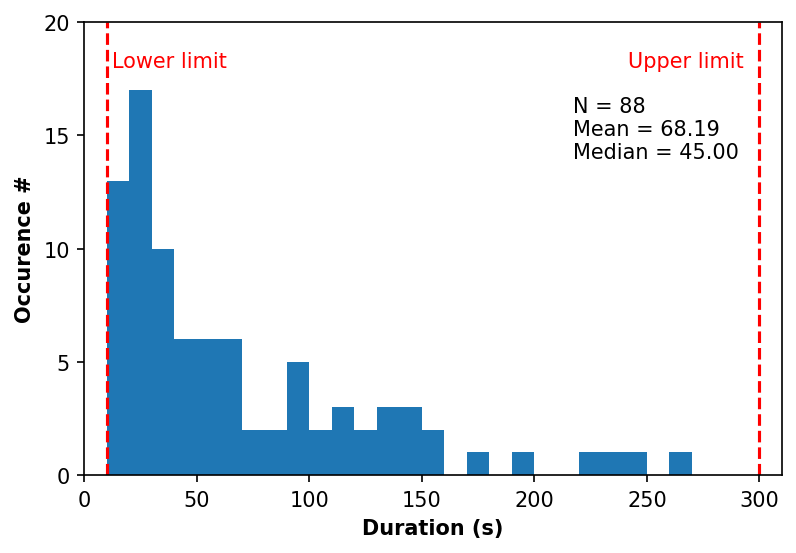

In [11]:
# Plot simpler histograms.
fig = plt.figure(dpi=150)
ax = plt.subplot(111)
ax.hist(deltat, bins=np.arange(0, 310, 10))
ax.axvline(10, ls='dashed', color='r')
ax.axvline(300, ls='dashed', color='r')
ax.set_xlim([0, 310])
ax.set_yticks([0, 5, 10, 15, 20])
ax.set_xlabel('Duration (s)', weight='bold')
ax.set_ylabel('Occurence #', weight='bold')
ax.text(0.70, 0.70, 'N = {:d}\nMean = {:.2f}\nMedian = {:.2f}'.format(len(deltat), np.mean(deltat), np.median(deltat)), transform=ax.transAxes)
ax.text(0.04, 0.9, 'Lower limit', color='r', transform=ax.transAxes)
ax.text(0.78, 0.9, 'Upper limit', color='r', transform=ax.transAxes)

fig.savefig('out_images/duration_histogram.png')
plt.show()